In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("combined_merged.csv")

df.head()

,DATE_TIME,PLANT_ID,AC_POWER,DC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,0.0,0.0,25.184316,22.857507,0.0
1,2020-05-15 00:00:00,4136001,0.0,0.0,27.004764,25.060789,0.0
2,2020-05-15 00:15:00,4135001,0.0,0.0,25.084589,22.761668,0.0
3,2020-05-15 00:15:00,4136001,0.0,0.0,26.880811,24.421869,0.0
4,2020-05-15 00:30:00,4135001,0.0,0.0,24.935753,22.592306,0.0


In [3]:
print("Dataset Shape:", df.shape)

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:", df.duplicated().sum())

print("\nPlant Distribution:")
print(df["PLANT_ID"].value_counts())

Dataset Shape: (6417, 7)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6417 entries, 0 to 6416
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   DATE_TIME            6417 non-null   object 
 1   PLANT_ID             6417 non-null   int64  
 2   AC_POWER             6417 non-null   float64
 3   DC_POWER             6417 non-null   float64
 4   AMBIENT_TEMPERATURE  6416 non-null   float64
 5   MODULE_TEMPERATURE   6416 non-null   float64
 6   IRRADIATION          6416 non-null   float64
dtypes: float64(5), int64(1), object(1)
memory usage: 351.1+ KB

Statistical Summary:


,PLANT_ID,AC_POWER,DC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
count,6.417000e+03,6417.000000,6417.000000,6416.000000,6416.000000,6416.000000
mean,4.135509e+06,5844.488687,36337.059265,26.834773,31.986625,0.231441
std,4.999770e+02,7576.456403,69577.597847,3.934008,11.836145,0.307142
min,4.135001e+06,0.000000,0.000000,20.398505,18.140415,0.000000
25%,4.135001e+06,0.000000,0.000000,23.673180,22.466628,0.000000
50%,4.136001e+06,639.907143,1264.839286,25.973933,26.478017,0.023582
75%,4.136001e+06,11898.133333,17790.186667,29.366598,40.932470,0.445586
max,4.136001e+06,29150.212499,298937.785710,39.181638,66.635953,1.221652



Missing Values:
DATE_TIME              0
PLANT_ID               0
AC_POWER               0
DC_POWER               0
AMBIENT_TEMPERATURE    1
MODULE_TEMPERATURE     1
IRRADIATION            1
dtype: int64

Duplicate Records: 0

Plant Distribution:
PLANT_ID
4136001    3259
4135001    3158
Name: count, dtype: int64


In [4]:
df["DATE_TIME"] = pd.to_datetime(df["DATE_TIME"])

print(df["DATE_TIME"].dtype)

print("Starting Date:", df["DATE_TIME"].min())
print("Ending Date:", df["DATE_TIME"].max())

datetime64[ns]
Starting Date: 2020-05-15 00:00:00
Ending Date: 2020-06-17 23:45:00


In [5]:
clean_df = df.copy()

In [6]:
print(clean_df[clean_df.isnull().any(axis=1)])

               DATE_TIME  PLANT_ID  AC_POWER  DC_POWER  AMBIENT_TEMPERATURE  \
3652 2020-06-03 14:00:00   4135001    2907.7   29698.0                  NaN   

      MODULE_TEMPERATURE  IRRADIATION  
3652                 NaN          NaN  


In [7]:
columns = [
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION"
]

for col in columns:
    clean_df[col] = clean_df.groupby("PLANT_ID")[col].transform(
        lambda x: x.fillna(x.median())
    )

In [8]:
print("Duplicate records:", clean_df.duplicated().sum())

print(
    "Duplicate plant timestamps:",
    clean_df.duplicated(subset=["PLANT_ID", "DATE_TIME"]).sum()
)

Duplicate records: 0
Duplicate plant timestamps: 0


In [9]:
numeric_columns = [
    "AC_POWER",
    "DC_POWER",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION"
]

for col in numeric_columns:
    print(col, ":", (clean_df[col] < 0).sum())

AC_POWER : 0
DC_POWER : 0
AMBIENT_TEMPERATURE : 0
MODULE_TEMPERATURE : 0
IRRADIATION : 0


In [10]:
clean_df = clean_df.sort_values(
    by=["PLANT_ID", "DATE_TIME"]
).reset_index(drop=True)

In [11]:
clean_df["TIME_DIFFERENCE"] = (
    clean_df.groupby("PLANT_ID")["DATE_TIME"]
    .diff()
)

print(
    clean_df.groupby("PLANT_ID")["TIME_DIFFERENCE"]
    .value_counts()
)

PLANT_ID  TIME_DIFFERENCE
4135001   0 days 00:15:00    3148
          0 days 00:30:00       2
          0 days 00:45:00       1
          0 days 01:00:00       1
          0 days 01:45:00       1
          0 days 03:00:00       1
          0 days 04:15:00       1
          0 days 08:00:00       1
          0 days 09:00:00       1
4136001   0 days 00:15:00    3253
          0 days 00:30:00       5
Name: count, dtype: int64


In [12]:
print("Final Shape:", clean_df.shape)

print("\nRemaining Missing Values:")
print(clean_df.isnull().sum())

print("\nRemaining Duplicates:")
print(clean_df.duplicated().sum())

print("\nPlant Distribution:")
print(clean_df["PLANT_ID"].value_counts())

Final Shape: (6417, 8)

Remaining Missing Values:
DATE_TIME              0
PLANT_ID               0
AC_POWER               0
DC_POWER               0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
TIME_DIFFERENCE        2
dtype: int64

Remaining Duplicates:
0

Plant Distribution:
PLANT_ID
4136001    3259
4135001    3158
Name: count, dtype: int64


In [13]:
sns.set_style("whitegrid")

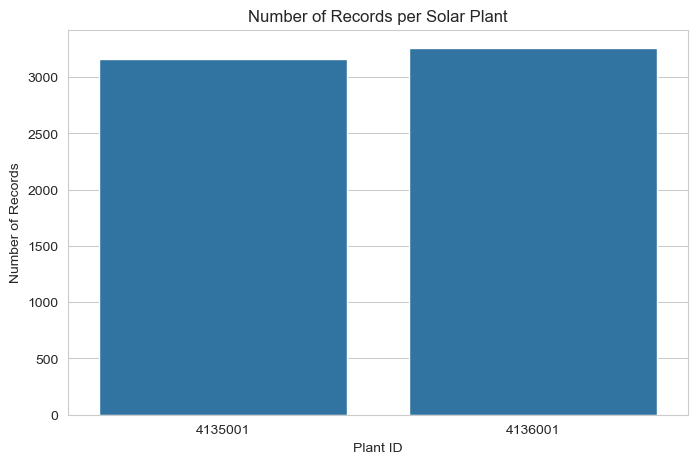

In [14]:
plt.figure(figsize=(8, 5))

sns.countplot(data=clean_df, x="PLANT_ID")

plt.title("Number of Records per Solar Plant")
plt.xlabel("Plant ID")
plt.ylabel("Number of Records")

plt.show()

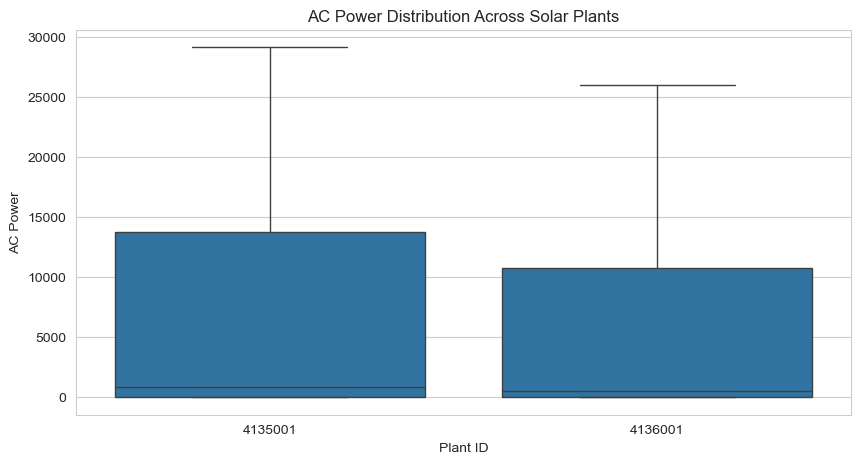

In [15]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=clean_df, x="PLANT_ID", y="AC_POWER")

plt.title("AC Power Distribution Across Solar Plants")
plt.xlabel("Plant ID")
plt.ylabel("AC Power")

plt.show()

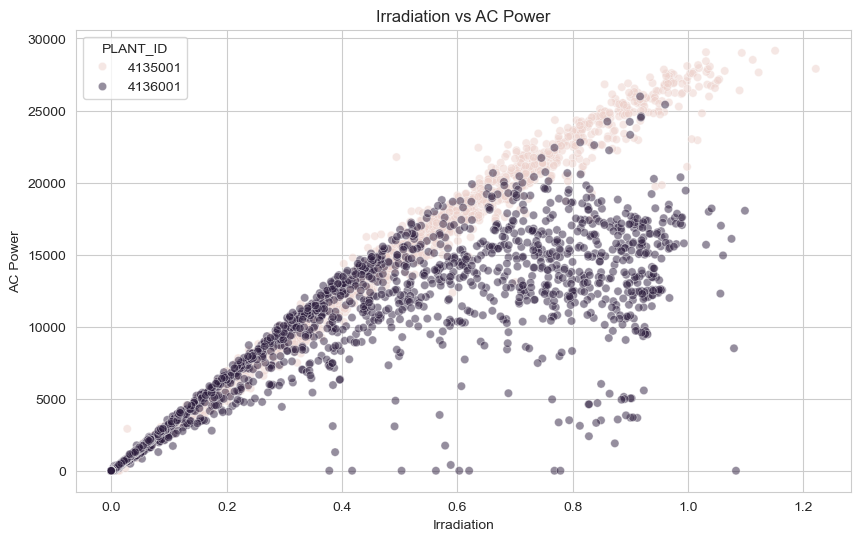

In [16]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=clean_df,
    x="IRRADIATION",
    y="AC_POWER",
    hue="PLANT_ID",
    alpha=0.5
)

plt.title("Irradiation vs AC Power")
plt.xlabel("Irradiation")
plt.ylabel("AC Power")

plt.show()

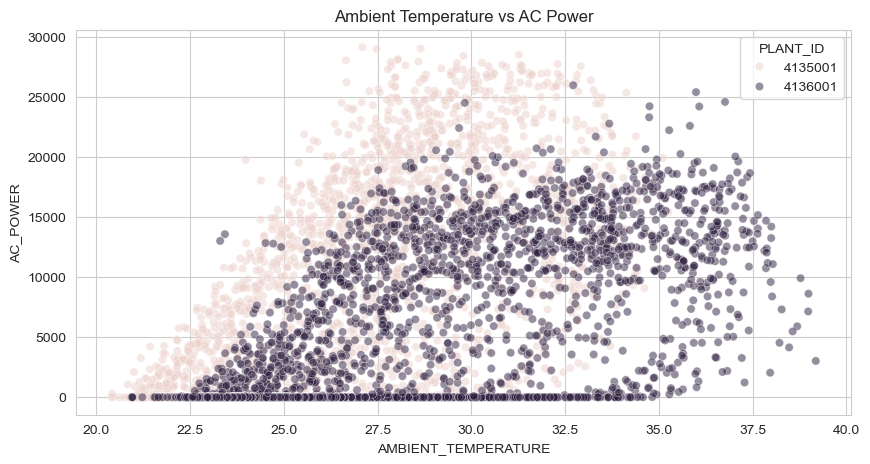

In [17]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=clean_df,
    x="AMBIENT_TEMPERATURE",
    y="AC_POWER",
    hue="PLANT_ID",
    alpha=0.5
)

plt.title("Ambient Temperature vs AC Power")
plt.show()

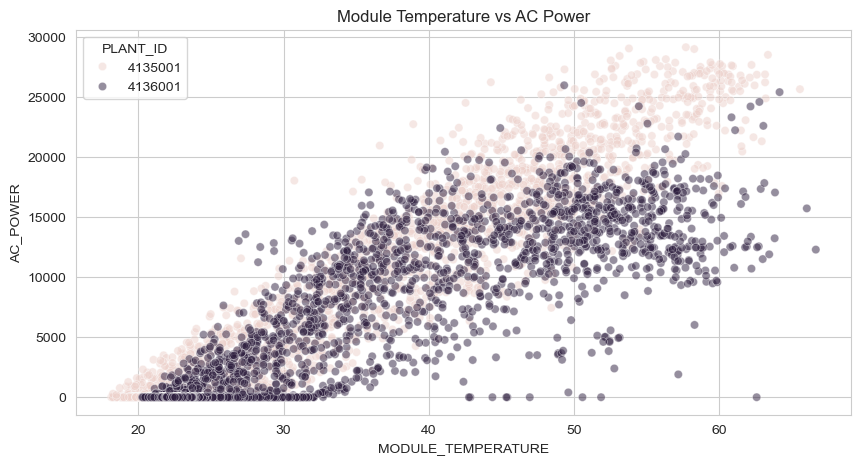

In [18]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=clean_df,
    x="MODULE_TEMPERATURE",
    y="AC_POWER",
    hue="PLANT_ID",
    alpha=0.5
)

plt.title("Module Temperature vs AC Power")
plt.show()

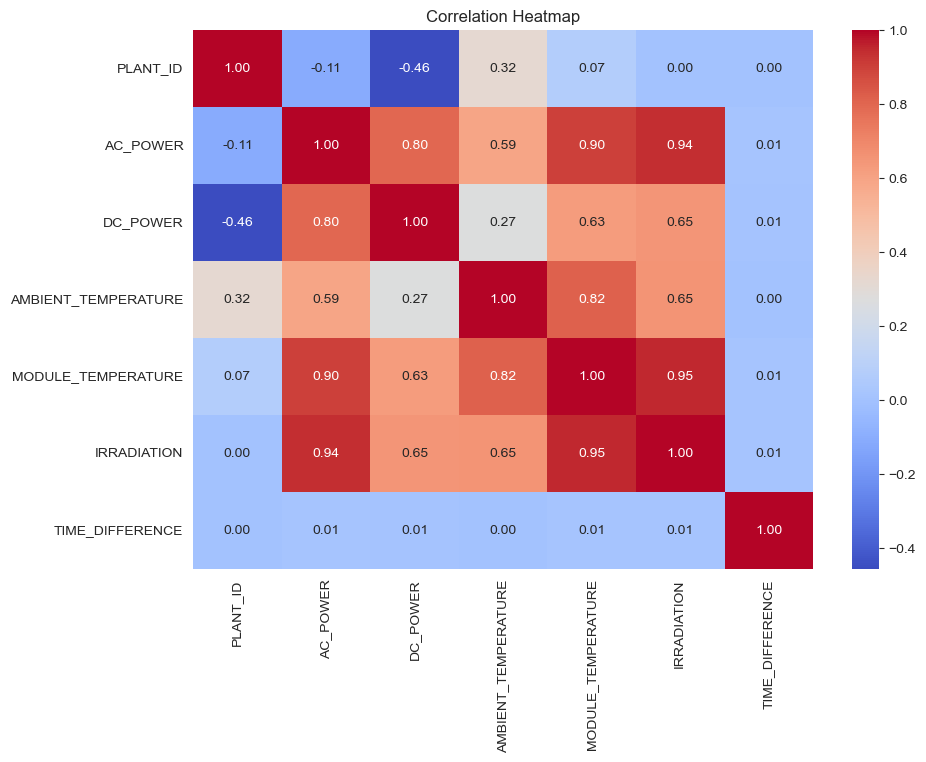

In [19]:
numeric_df = clean_df.select_dtypes(include=np.number)

correlation = numeric_df.corr()

plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

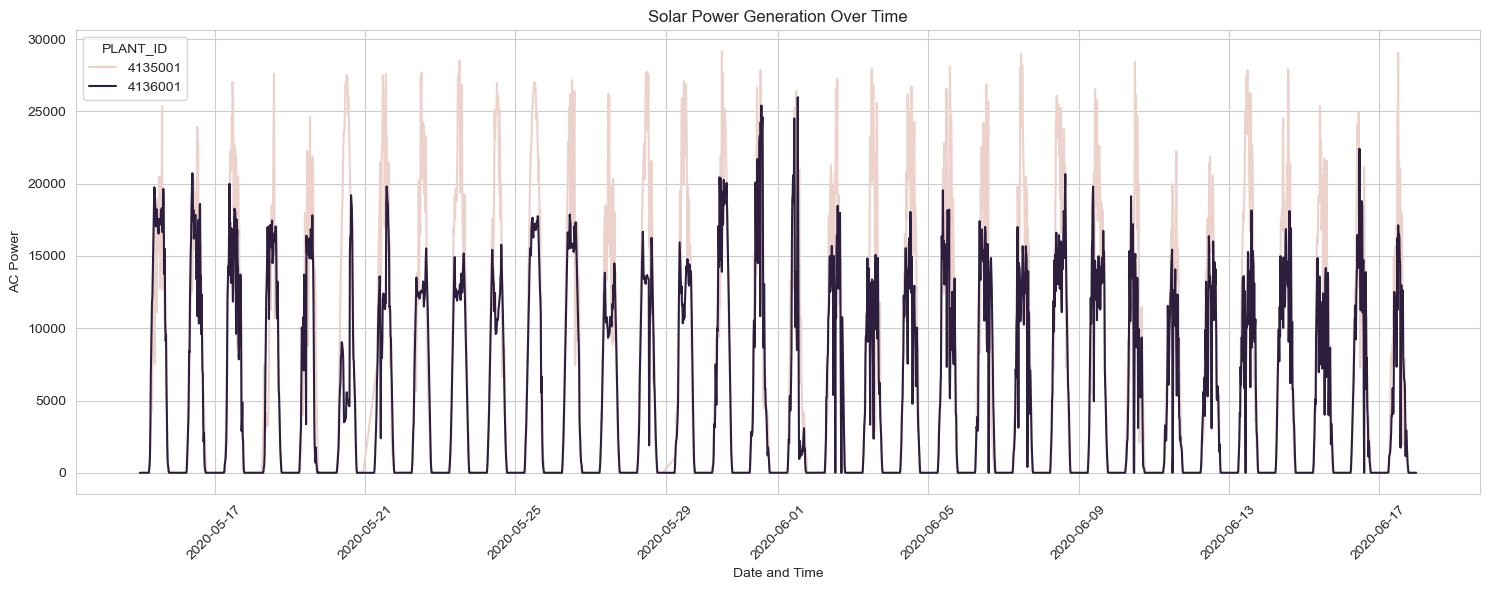

In [20]:
plt.figure(figsize=(15, 6))

sns.lineplot(
    data=clean_df,
    x="DATE_TIME",
    y="AC_POWER",
    hue="PLANT_ID",
    errorbar=None
)

plt.title("Solar Power Generation Over Time")
plt.xlabel("Date and Time")
plt.ylabel("AC Power")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [21]:
clean_df["HOUR"] = clean_df["DATE_TIME"].dt.hour

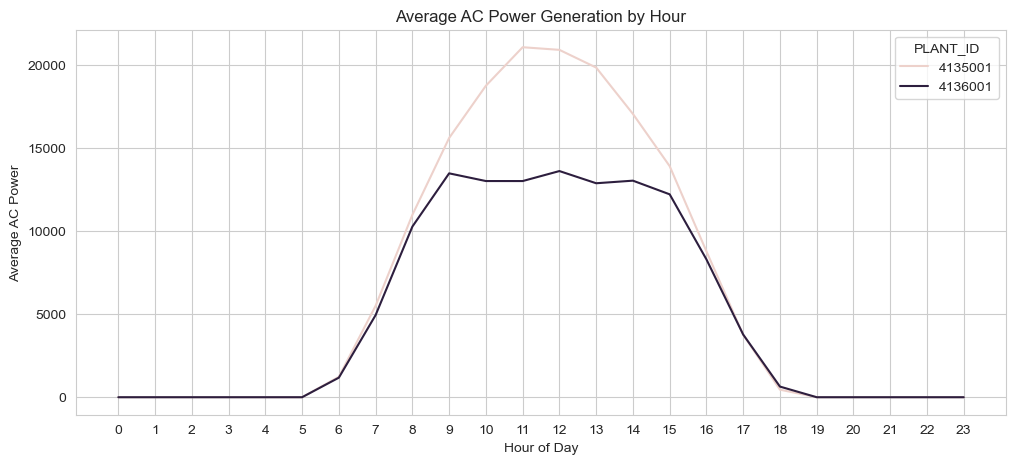

In [22]:
plt.figure(figsize=(12, 5))

sns.lineplot(
    data=clean_df,
    x="HOUR",
    y="AC_POWER",
    hue="PLANT_ID",
    errorbar=None
)

plt.title("Average AC Power Generation by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average AC Power")

plt.xticks(range(0, 24))

plt.show()

In [23]:
clean_df.isnull().sum()

DATE_TIME              0
PLANT_ID               0
AC_POWER               0
DC_POWER               0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
TIME_DIFFERENCE        2
HOUR                   0
dtype: int64

In [24]:
clean_df.head()

,DATE_TIME,PLANT_ID,AC_POWER,DC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,TIME_DIFFERENCE,HOUR
0,2020-05-15 00:00:00,4135001,0.0,0.0,25.184316,22.857507,0.0,NaT,0
1,2020-05-15 00:15:00,4135001,0.0,0.0,25.084589,22.761668,0.0,0 days 00:15:00,0
2,2020-05-15 00:30:00,4135001,0.0,0.0,24.935753,22.592306,0.0,0 days 00:15:00,0
3,2020-05-15 00:45:00,4135001,0.0,0.0,24.846130,22.360852,0.0,0 days 00:15:00,0
4,2020-05-15 01:00:00,4135001,0.0,0.0,24.621525,22.165423,0.0,0 days 00:15:00,1


In [25]:
minutes = (
    clean_df["DATE_TIME"].dt.hour * 60 +
    clean_df["DATE_TIME"].dt.minute
)

clean_df["TIME_SIN"] = np.sin(2 * np.pi * minutes / 1440)

clean_df["TIME_COS"] = np.cos(2 * np.pi * minutes / 1440)

In [26]:
timestamps = clean_df["DATE_TIME"].copy()

In [27]:
X = clean_df[
    [
        "PLANT_ID",
        "TIME_SIN",
        "TIME_COS",
        "AMBIENT_TEMPERATURE",
        "MODULE_TEMPERATURE",
        "IRRADIATION"
    ]
]

y = clean_df["AC_POWER"]

In [28]:
print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nInput Features:")
print(X.head())

print("\nTarget:")
print(y.head())

Input Shape: (6417, 6)
Target Shape: (6417,)

Input Features:
   PLANT_ID  TIME_SIN  TIME_COS  AMBIENT_TEMPERATURE  MODULE_TEMPERATURE  \
0   4135001  0.000000  1.000000            25.184316           22.857507   
1   4135001  0.065403  0.997859            25.084589           22.761668   
2   4135001  0.130526  0.991445            24.935753           22.592306   
3   4135001  0.195090  0.980785            24.846130           22.360852   
4   4135001  0.258819  0.965926            24.621525           22.165423   

   IRRADIATION  
0          0.0  
1          0.0  
2          0.0  
3          0.0  
4          0.0  

Target:
0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: AC_POWER, dtype: float64


In [29]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

In [30]:
categorical_features = ["PLANT_ID"]

numerical_features = [
    "TIME_SIN",
    "TIME_COS",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION"
]

In [31]:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [32]:
print("Missing values in X:")
print(X.isnull().sum())

print("\nMissing values in y:")
print(y.isnull().sum())

print("\nUnique Plant IDs:")
print(X["PLANT_ID"].unique())

print("\nFinal Features:")
print(X.columns.tolist())

Missing values in X:
PLANT_ID               0
TIME_SIN               0
TIME_COS               0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
dtype: int64

Missing values in y:
0

Unique Plant IDs:
[4135001 4136001]

Final Features:
['PLANT_ID', 'TIME_SIN', 'TIME_COS', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE', 'IRRADIATION']


In [33]:
clean_df.isnull().sum()

DATE_TIME              0
PLANT_ID               0
AC_POWER               0
DC_POWER               0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
TIME_DIFFERENCE        2
HOUR                   0
TIME_SIN               0
TIME_COS               0
dtype: int64

In [34]:
clean_df.drop(columns=["TIME_DIFFERENCE"], inplace=True)

In [35]:
clean_df.isnull().sum()

DATE_TIME              0
PLANT_ID               0
AC_POWER               0
DC_POWER               0
AMBIENT_TEMPERATURE    0
MODULE_TEMPERATURE     0
IRRADIATION            0
HOUR                   0
TIME_SIN               0
TIME_COS               0
dtype: int64

In [36]:
#splitting

In [37]:
from sklearn.model_selection import train_test_split

clean_df = clean_df.sort_values("DATE_TIME").reset_index(drop=True)

X = clean_df[
    [
        "PLANT_ID",
        "TIME_SIN",
        "TIME_COS",
        "AMBIENT_TEMPERATURE",
        "MODULE_TEMPERATURE",
        "IRRADIATION"
    ]
]

y = clean_df["AC_POWER"]

In [38]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    shuffle=False
)

In [39]:
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    shuffle=False
)

In [40]:
from sklearn.model_selection import train_test_split
import numpy as np

unique_times = np.sort(clean_df["DATE_TIME"].unique())

train_times, temp_times = train_test_split(
    unique_times,
    test_size=0.30,
    shuffle=False
)

val_times, test_times = train_test_split(
    temp_times,
    test_size=0.50,
    shuffle=False
)

In [41]:
train_mask = clean_df["DATE_TIME"].isin(train_times)
val_mask = clean_df["DATE_TIME"].isin(val_times)
test_mask = clean_df["DATE_TIME"].isin(test_times)

X_train = X.loc[train_mask]
X_val = X.loc[val_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_val = y.loc[val_mask]
y_test = y.loc[test_mask]

In [42]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nTraining period:")
print(train_times[0], "to", train_times[-1])

print("\nValidation period:")
print(val_times[0], "to", val_times[-1])

print("\nTesting period:")
print(test_times[0], "to", test_times[-1])

Training: (4461, 6)
Validation: (978, 6)
Testing: (978, 6)

Training period:
2020-05-15T00:00:00.000000000 to 2020-06-07T19:00:00.000000000

Validation period:
2020-06-07T19:15:00.000000000 to 2020-06-12T21:15:00.000000000

Testing period:
2020-06-12T21:30:00.000000000 to 2020-06-17T23:45:00.000000000


In [43]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numerical_features = [
    "TIME_SIN",
    "TIME_COS",
    "AMBIENT_TEMPERATURE",
    "MODULE_TEMPERATURE",
    "IRRADIATION"
]

categorical_features = ["PLANT_ID"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [44]:
"""Linear Regression"""
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [45]:
lr_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('model', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [46]:
y_pred = lr_model.predict(X_val)

In [47]:
comparison = pd.DataFrame({
    "Actual": y_val.values[:10],
    "Predicted": y_pred[:10]
})

print(comparison)

   Actual    Predicted
0     0.0  1229.599951
1     0.0   -20.631146
2     0.0  1143.203887
3     0.0   -95.204545
4     0.0  1097.002157
5     0.0  -188.920940
6     0.0  1019.312455
7     0.0  -302.842516
8     0.0  -372.379167
9     0.0   984.935991


In [48]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

mae = mean_absolute_error(y_val, y_pred)
mse = mean_squared_error(y_val, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_val, y_pred)

print("Linear Regression Results")
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

Linear Regression Results
MAE: 1513.872273052236
MSE: 5064404.0952657005
RMSE: 2250.4230925018746
R2 Score: 0.9001359383752043


In [49]:
diagnostics = clean_df.loc[
    X_val.index,
    [
        "DATE_TIME",
        "PLANT_ID",
        "IRRADIATION",
        "AMBIENT_TEMPERATURE",
        "MODULE_TEMPERATURE"
    ]
].copy()

diagnostics["Actual"] = y_val
diagnostics["Predicted"] = y_pred
diagnostics["Error"] = diagnostics["Actual"] - diagnostics["Predicted"]

print(diagnostics.head(15))

               DATE_TIME  PLANT_ID  IRRADIATION  AMBIENT_TEMPERATURE  \
4461 2020-06-07 19:15:00   4135001          0.0            24.971708   
4462 2020-06-07 19:15:00   4136001          0.0            28.543777   
4463 2020-06-07 19:30:00   4135001          0.0            24.678800   
4464 2020-06-07 19:30:00   4136001          0.0            28.209815   
4465 2020-06-07 19:45:00   4135001          0.0            24.436839   
4466 2020-06-07 19:45:00   4136001          0.0            28.011380   
4467 2020-06-07 20:00:00   4135001          0.0            24.214486   
4468 2020-06-07 20:00:00   4136001          0.0            27.747610   
4469 2020-06-07 20:15:00   4136001          0.0            27.481502   
4470 2020-06-07 20:15:00   4135001          0.0            24.090845   
4471 2020-06-07 20:30:00   4136001          0.0            27.152644   
4472 2020-06-07 20:30:00   4135001          0.0            24.030011   
4473 2020-06-07 20:45:00   4136001          0.0            26.81

In [50]:
for plant in diagnostics["PLANT_ID"].unique():

    plant_data = diagnostics[
        diagnostics["PLANT_ID"] == plant
    ]

    print("\nPlant:", plant)

    print("MAE:", mean_absolute_error(
        plant_data["Actual"],
        plant_data["Predicted"]
    ))

    print("RMSE:", np.sqrt(mean_squared_error(
        plant_data["Actual"],
        plant_data["Predicted"]
    )))

    print("R2:", r2_score(
        plant_data["Actual"],
        plant_data["Predicted"]
    ))


Plant: 4135001
MAE: 1374.0619505934221
RMSE: 1773.4977204916659
R2: 0.9517195036236429

Plant: 4136001
MAE: 1653.6825955110498
RMSE: 2642.6339182607694
R2: 0.8010178875511429


In [51]:
print("Validation target statistics:")
print(y_val.describe())

print("\nNegative predictions:", (y_pred < 0).sum())
print("Total predictions:", len(y_pred))

Validation target statistics:
count      978.000000
mean      5383.562889
std       7124.948153
min          0.000000
25%          0.000000
50%        281.126667
75%      11156.490595
max      28424.751787
Name: AC_POWER, dtype: float64

Negative predictions: 204
Total predictions: 978


In [74]:
"""RIDGE"""

from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline

ridge_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Ridge())
    ]
)
ridge_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
ridge_grid = GridSearchCV(
    estimator=ridge_model,
    param_grid=ridge_param_grid,
    scoring="neg_mean_squared_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)



In [75]:
ridge_grid.fit(X_train, y_train)

Fitting 5 folds for each of 7 candidates, totalling 35 fits


,estimator,"Pipeline(step...l', Ridge())])"
,param_grid,"{'model__alpha': [0.001, 0.01, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,"[(array([ 0, ...55, 756, 757]), ...), (array([ 0, ...shape=(1463,)), ...), ...]"
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [76]:
print("Best Parameters:")
print(ridge_grid.best_params_)

print("\nBest CV RMSE:")
print(np.sqrt(-ridge_grid.best_score_))

Best Parameters:
{'model__alpha': 100}

Best CV RMSE:
2616.5403054442704


In [77]:
best_ridge = ridge_grid.best_estimator_

ridge_tuned_pred = best_ridge.predict(X_val)

ridge_tuned_mae = mean_absolute_error(y_val, ridge_tuned_pred)
ridge_tuned_mse = mean_squared_error(y_val, ridge_tuned_pred)
ridge_tuned_rmse = np.sqrt(ridge_tuned_mse)
ridge_tuned_r2 = r2_score(y_val, ridge_tuned_pred)

print("Tuned Ridge Results")
print("MAE:", ridge_tuned_mae)
print("MSE:", ridge_tuned_mse)
print("RMSE:", ridge_tuned_rmse)
print("R2:", ridge_tuned_r2)

Tuned Ridge Results
MAE: 1533.7613556567442
MSE: 5076008.938818029
RMSE: 2252.9999864221104
R2: 0.8999071045795878


In [78]:
"""LASSO"""
from sklearn.linear_model import Lasso

lasso_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", Lasso(max_iter=10000))
    ]
)
lasso_param_grid = {
    "model__alpha": [0.001, 0.01, 0.1, 1, 10, 100, 1000]
}
lasso_grid = GridSearchCV(
    estimator=lasso_model,
    param_grid=lasso_param_grid,
    scoring="neg_mean_squared_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)



In [79]:
lasso_grid.fit(X_train, y_train)

Fitting 5 folds for each of 7 candidates, totalling 35 fits


,estimator,Pipeline(step...iter=10000))])
,param_grid,"{'model__alpha': [0.001, 0.01, ...]}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,"[(array([ 0, ...55, 756, 757]), ...), (array([ 0, ...shape=(1463,)), ...), ...]"
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [80]:
print("Best Parameters:")
print(lasso_grid.best_params_)

print("\nBest Cross Validation RMSE:")
print(np.sqrt(-lasso_grid.best_score_))

Best Parameters:
{'model__alpha': 10}

Best Cross Validation RMSE:
2652.802632072583


In [81]:
best_lasso = lasso_grid.best_estimator_

lasso_tuned_pred = best_lasso.predict(X_val)

lasso_tuned_mae = mean_absolute_error(y_val, lasso_tuned_pred)
lasso_tuned_mse = mean_squared_error(y_val, lasso_tuned_pred)
lasso_tuned_rmse = np.sqrt(lasso_tuned_mse)
lasso_tuned_r2 = r2_score(y_val, lasso_tuned_pred)

print("Tuned Lasso Results")
print("MAE:", lasso_tuned_mae)
print("MSE:", lasso_tuned_mse)
print("RMSE:", lasso_tuned_rmse)
print("R2:", lasso_tuned_r2)

Tuned Lasso Results
MAE: 1515.2998667464083
MSE: 5067610.29832227
RMSE: 2251.1353354079515
R2: 0.9000727158412991


In [82]:
best_lasso = lasso_grid.best_estimator_

lasso_tuned_pred = best_lasso.predict(X_val)

lasso_tuned_mae = mean_absolute_error(y_val, lasso_tuned_pred)
lasso_tuned_mse = mean_squared_error(y_val, lasso_tuned_pred)
lasso_tuned_rmse = np.sqrt(lasso_tuned_mse)
lasso_tuned_r2 = r2_score(y_val, lasso_tuned_pred)

print("Tuned Lasso Results")
print("MAE:", lasso_tuned_mae)
print("MSE:", lasso_tuned_mse)
print("RMSE:", lasso_tuned_rmse)
print("R2:", lasso_tuned_r2)

Tuned Lasso Results
MAE: 1515.2998667464083
MSE: 5067610.29832227
RMSE: 2251.1353354079515
R2: 0.9000727158412991


In [62]:
"""SVR"""
from sklearn.svm import SVR
from sklearn.pipeline import Pipeline

svr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", SVR())
    ]
)

In [63]:
from sklearn.model_selection import TimeSeriesSplit

train_row_times = clean_df.loc[X_train.index, "DATE_TIME"]

unique_train_times = np.sort(train_row_times.unique())

tscv = TimeSeriesSplit(n_splits=5)

cv_splits = []

for train_idx, val_idx in tscv.split(unique_train_times):

    fold_train_times = unique_train_times[train_idx]
    fold_val_times = unique_train_times[val_idx]

    fold_train_rows = np.flatnonzero(
        train_row_times.isin(fold_train_times).to_numpy()
    )

    fold_val_rows = np.flatnonzero(
        train_row_times.isin(fold_val_times).to_numpy()
    )

    cv_splits.append((fold_train_rows, fold_val_rows))

In [64]:
param_grid = [
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__epsilon": [0.1, 0.5, 1.0],
        "model__gamma": ["scale", "auto"]
    },
    {
        "model__kernel": ["linear"],
        "model__C": [0.1, 1, 10, 100],
        "model__epsilon": [0.1, 0.5, 1.0]
    }
]

In [65]:
from sklearn.model_selection import GridSearchCV

svr_grid = GridSearchCV(
    estimator=svr_model,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)

svr_grid.fit(X_train, y_train)

Fitting 5 folds for each of 36 candidates, totalling 180 fits


,estimator,"Pipeline(step...del', SVR())])"
,param_grid,"[{'model__C': [0.1, 1, ...], 'model__epsilon': [0.1, 0.5, ...], 'model__gamma': ['scale', 'auto'], 'model__kernel': ['rbf']}, {'model__C': [0.1, 1, ...], 'model__epsilon': [0.1, 0.5, ...], 'model__kernel': ['linear']}]"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,"[(array([ 0, ...55, 756, 757]), ...), (array([ 0, ...shape=(1463,)), ...), ...]"
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [66]:
print("Best Parameters:")
print(svr_grid.best_params_)

print("\nBest Cross Validation RMSE:")
print(np.sqrt(-svr_grid.best_score_))

Best Parameters:
{'model__C': 100, 'model__epsilon': 0.1, 'model__gamma': 'auto', 'model__kernel': 'rbf'}

Best Cross Validation RMSE:
2495.7588267420083


In [67]:
best_svr = svr_grid.best_estimator_

svr_pred = best_svr.predict(X_val)

svr_mae = mean_absolute_error(y_val, svr_pred)
svr_mse = mean_squared_error(y_val, svr_pred)
svr_rmse = np.sqrt(svr_mse)
svr_r2 = r2_score(y_val, svr_pred)

print("Tuned SVR Results")
print("MAE:", svr_mae)
print("MSE:", svr_mse)
print("RMSE:", svr_rmse)
print("R2:", svr_r2)

Tuned SVR Results
MAE: 753.3304961755151
MSE: 2722605.399490949
RMSE: 1650.0319389305619
R2: 0.9463134401836272


In [68]:
"""RANDOM FOREST"""
rf_preprocessor = ColumnTransformer(
    transformers=[
        ("num", "passthrough", numerical_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [69]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        ("model", RandomForestRegressor(
            random_state=42,
            n_jobs=1
        ))
    ]
)

In [70]:
rf_param_grid = {
    "model__n_estimators": [200, 400],
    "model__max_depth": [None, 20],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2],
    "model__max_features": ["sqrt", 1.0]
}

In [71]:
rf_grid = GridSearchCV(
    estimator=rf_model,
    param_grid=rf_param_grid,
    scoring="neg_mean_squared_error",
    cv=cv_splits,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

Fitting 5 folds for each of 32 candidates, totalling 160 fits


,estimator,Pipeline(step...m_state=42))])
,param_grid,"{'model__max_depth': [None, 20], 'model__max_features': ['sqrt', 1.0], 'model__min_samples_leaf': [1, 2], 'model__min_samples_split': [2, 5], ...}"
,scoring,'neg_mean_squared_error'
,n_jobs,-1
,refit,True
,cv,"[(array([ 0, ...55, 756, 757]), ...), (array([ 0, ...shape=(1463,)), ...), ...]"
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [72]:
print("Best Parameters:")
print(rf_grid.best_params_)

print("\nBest Cross Validation RMSE:")
print(np.sqrt(-rf_grid.best_score_))

Best Parameters:
{'model__max_depth': None, 'model__max_features': 1.0, 'model__min_samples_leaf': 2, 'model__min_samples_split': 5, 'model__n_estimators': 200}

Best Cross Validation RMSE:
1880.1989020459


In [73]:
best_rf = rf_grid.best_estimator_

rf_pred = best_rf.predict(X_val)

rf_mae = mean_absolute_error(y_val, rf_pred)
rf_mse = mean_squared_error(y_val, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_val, rf_pred)

print("Tuned Random Forest Results")
print("MAE:", rf_mae)
print("MSE:", rf_mse)
print("RMSE:", rf_rmse)
print("R2:", rf_r2)

Tuned Random Forest Results
MAE: 414.6255954386023
MSE: 1413388.1217562347
RMSE: 1188.860009318269
R2: 0.9721296571450992


In [83]:
"""COMPARISON"""
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Tuned Ridge",
        "Tuned Lasso",
        "Tuned SVR",
        "Tuned Random Forest"
    ],

    "MAE": [
        mae,
        ridge_tuned_mae,
        lasso_tuned_mae,
        svr_mae,
        rf_mae
    ],

    "RMSE": [
        rmse,
        ridge_tuned_rmse,
        lasso_tuned_rmse,
        svr_rmse,
        rf_rmse
    ],

    "R2": [
        r2,
        ridge_tuned_r2,
        lasso_tuned_r2,
        svr_r2,
        rf_r2
    ]
})

results = results.sort_values(
    by="RMSE"
).reset_index(drop=True)

print(results)

                 Model          MAE         RMSE        R2
0  Tuned Random Forest   414.625595  1188.860009  0.972130
1            Tuned SVR   753.330496  1650.031939  0.946313
2    Linear Regression  1513.872273  2250.423093  0.900136
3          Tuned Lasso  1515.299867  2251.135335  0.900073
4          Tuned Ridge  1533.761356  2252.999986  0.899907


In [84]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

rf_train_pred = best_rf.predict(X_train)

print("TRAINING RESULTS")
print("MAE:", mean_absolute_error(y_train, rf_train_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_train, rf_train_pred)))
print("R2:", r2_score(y_train, rf_train_pred))

print("\nVALIDATION RESULTS")
print("MAE:", mean_absolute_error(y_val, rf_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_val, rf_pred)))
print("R2:", r2_score(y_val, rf_pred))

TRAINING RESULTS
MAE: 285.8105511790352
RMSE: 761.7510398100379
R2: 0.9903821410046609

VALIDATION RESULTS
MAE: 414.6255954386023
RMSE: 1188.860009318269
R2: 0.9721296571450992


In [85]:
diagnostics = clean_df.loc[
    X_val.index,
    ["DATE_TIME", "PLANT_ID", "IRRADIATION"]
].copy()

diagnostics["Actual"] = y_val
diagnostics["Predicted"] = rf_pred
diagnostics["Error"] = diagnostics["Actual"] - diagnostics["Predicted"]

for plant in diagnostics["PLANT_ID"].unique():

    plant_data = diagnostics[
        diagnostics["PLANT_ID"] == plant
    ]

    print("\nPlant:", plant)
    print("MAE:", mean_absolute_error(
        plant_data["Actual"], plant_data["Predicted"]
    ))
    print("RMSE:", np.sqrt(mean_squared_error(
        plant_data["Actual"], plant_data["Predicted"]
    )))
    print("R2:", r2_score(
        plant_data["Actual"], plant_data["Predicted"]
    ))


Plant: 4135001
MAE: 225.34735716198236
RMSE: 453.8135914698787
R2: 0.9968387018693471

Plant: 4136001
MAE: 603.9038337152223
RMSE: 1618.8976087787885
R2: 0.9253243879920866


In [86]:
"""model evaluation on unseen data"""
test_pred = best_rf.predict(X_test)

test_mae = mean_absolute_error(y_test, test_pred)
test_mse = mean_squared_error(y_test, test_pred)
test_rmse = np.sqrt(test_mse)
test_r2 = r2_score(y_test, test_pred)

print("FINAL TEST RESULTS")
print("MAE:", test_mae)
print("RMSE:", test_rmse)
print("R2:", test_r2)

FINAL TEST RESULTS
MAE: 500.71538589439444
RMSE: 1363.4173142864076
R2: 0.962806558962751


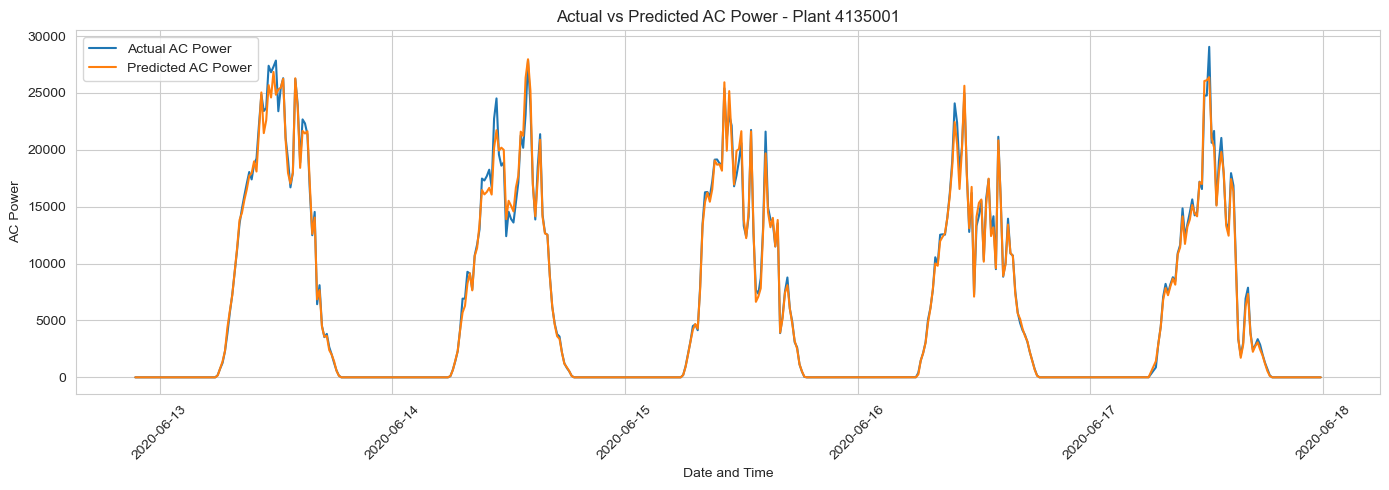

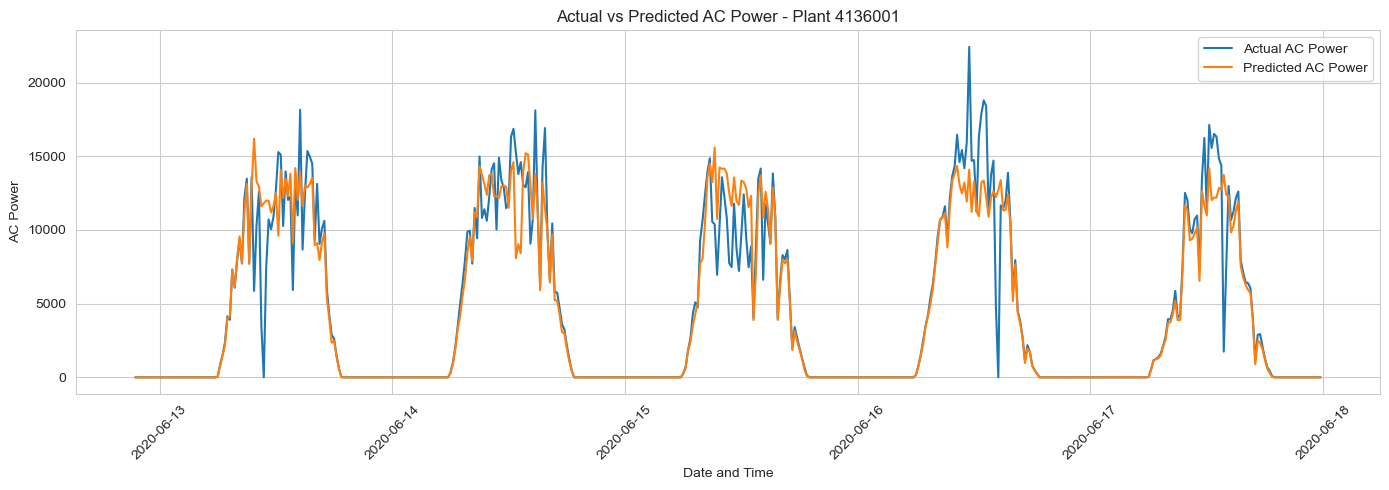

In [88]:
"""deviation"""
test_results = clean_df.loc[X_test.index].copy()

test_results["Actual_AC_POWER"] = y_test
test_results["Predicted_AC_POWER"] = test_pred
import matplotlib.pyplot as plt

for plant in test_results["PLANT_ID"].unique():

    data = test_results[
        test_results["PLANT_ID"] == plant
    ].sort_values("DATE_TIME")

    plt.figure(figsize=(14, 5))

    plt.plot(data["DATE_TIME"], data["Actual_AC_POWER"],
             label="Actual AC Power")

    plt.plot(data["DATE_TIME"], data["Predicted_AC_POWER"],
             label="Predicted AC Power")

    plt.title(f"Actual vs Predicted AC Power - Plant {plant}")
    plt.xlabel("Date and Time")
    plt.ylabel("AC Power")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

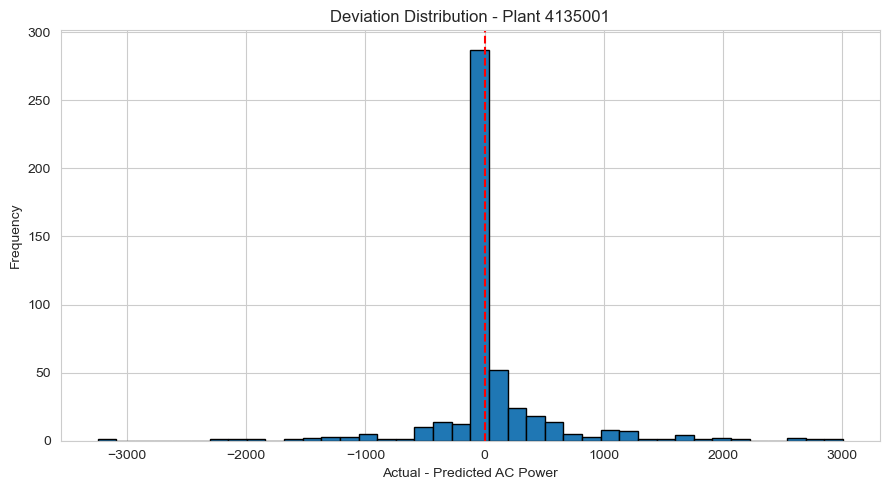

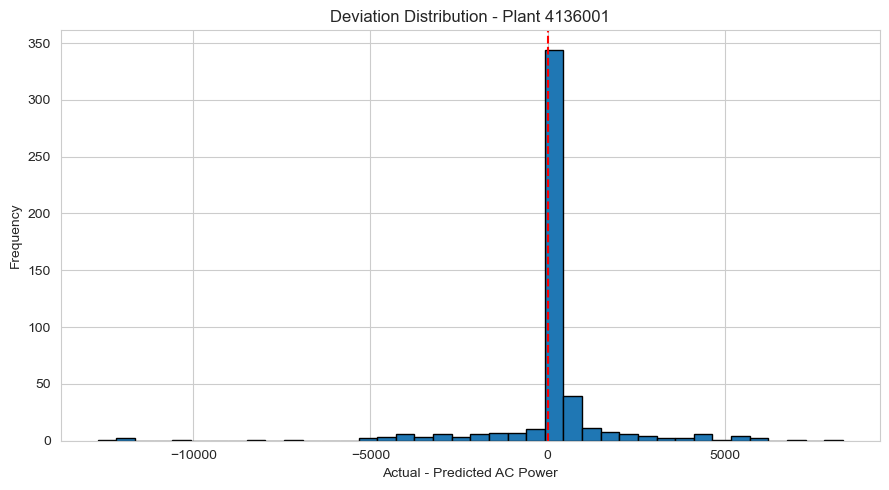

In [90]:
test_results["Deviation"] = (
    test_results["Actual_AC_POWER"] -
    test_results["Predicted_AC_POWER"]
)
for plant in test_results["PLANT_ID"].unique():

    data = test_results[
        test_results["PLANT_ID"] == plant
    ]

    plt.figure(figsize=(9, 5))

    plt.hist(data["Deviation"], bins=40, edgecolor="black")

    plt.axvline(0, color="red", linestyle="--")

    plt.title(f"Deviation Distribution - Plant {plant}")
    plt.xlabel("Actual - Predicted AC Power")
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

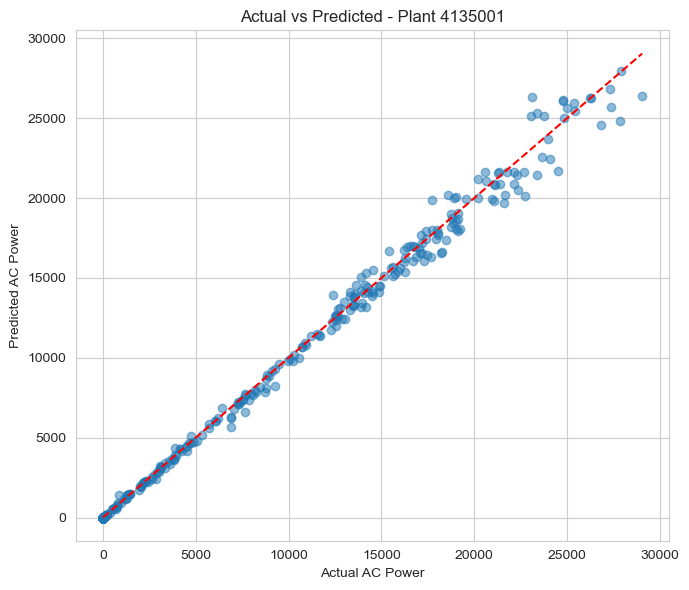

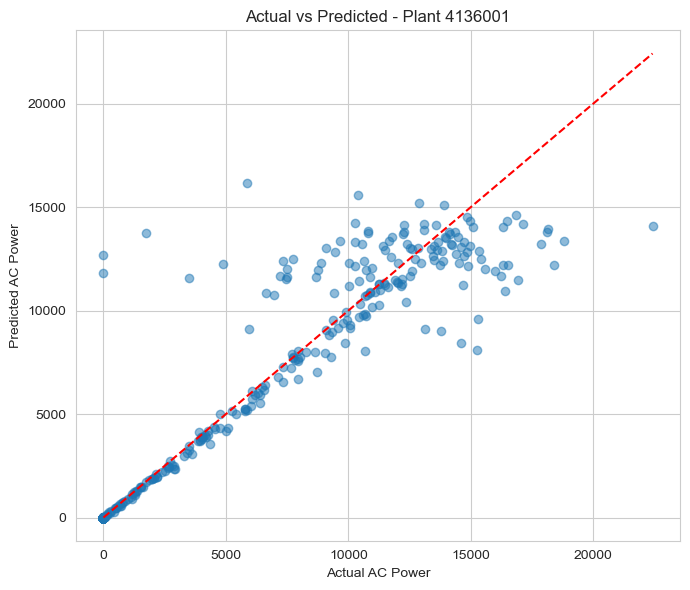

In [91]:
for plant in test_results["PLANT_ID"].unique():

    data = test_results[
        test_results["PLANT_ID"] == plant
    ]

    plt.figure(figsize=(7, 6))

    plt.scatter(
        data["Actual_AC_POWER"],
        data["Predicted_AC_POWER"],
        alpha=0.5
    )

    plt.plot([0, data["Actual_AC_POWER"].max()],
             [0, data["Actual_AC_POWER"].max()],
             "r--")

    plt.title(f"Actual vs Predicted - Plant {plant}")
    plt.xlabel("Actual AC Power")
    plt.ylabel("Predicted AC Power")
    plt.tight_layout()
    plt.show()

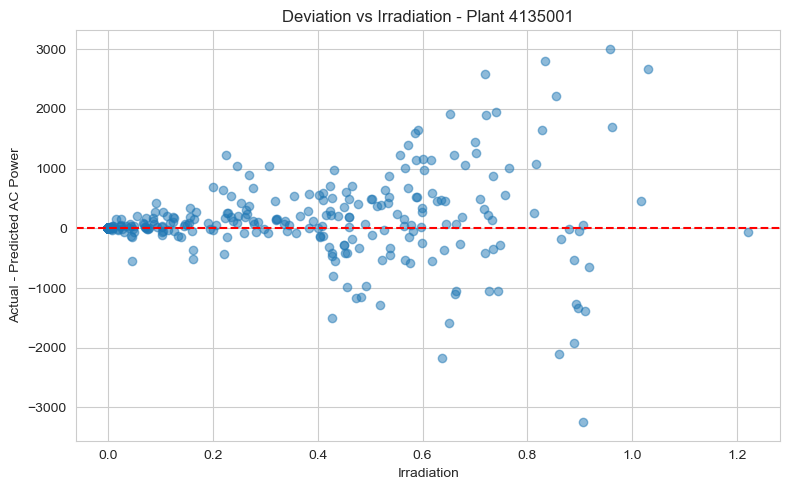

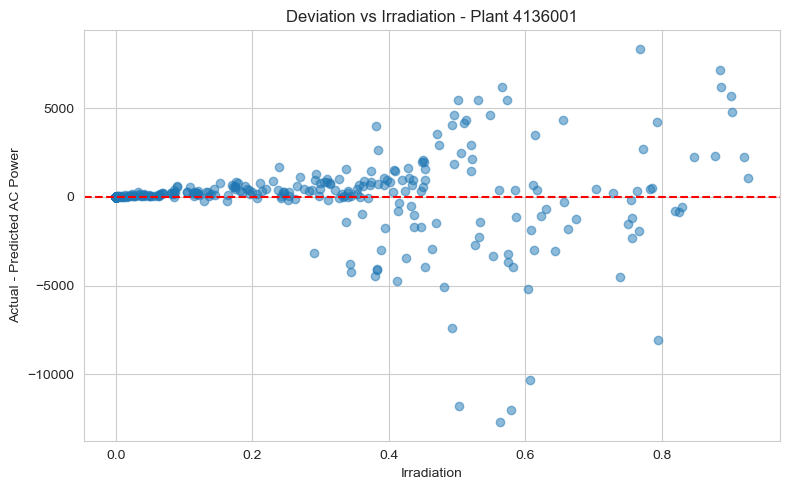

In [92]:
for plant in test_results["PLANT_ID"].unique():

    data = test_results[
        test_results["PLANT_ID"] == plant
    ]

    plt.figure(figsize=(8, 5))

    plt.scatter(
        data["IRRADIATION"],
        data["Deviation"],
        alpha=0.5
    )

    plt.axhline(0, color="red", linestyle="--")

    plt.title(f"Deviation vs Irradiation - Plant {plant}")
    plt.xlabel("Irradiation")
    plt.ylabel("Actual - Predicted AC Power")
    plt.tight_layout()
    plt.show()

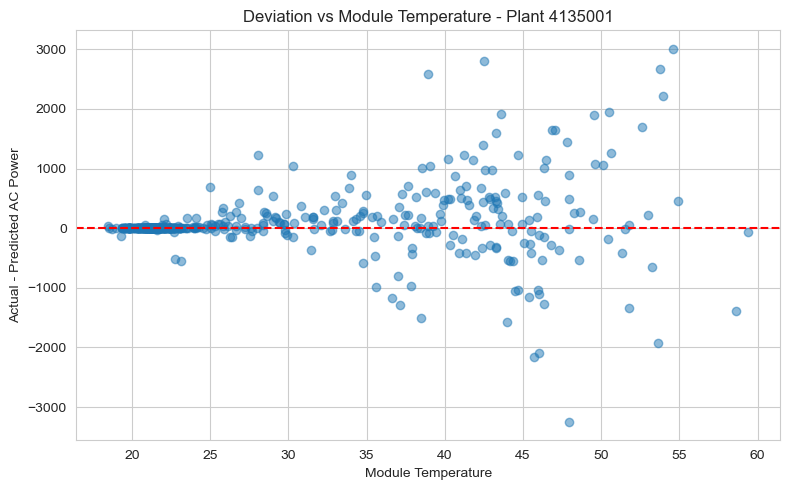

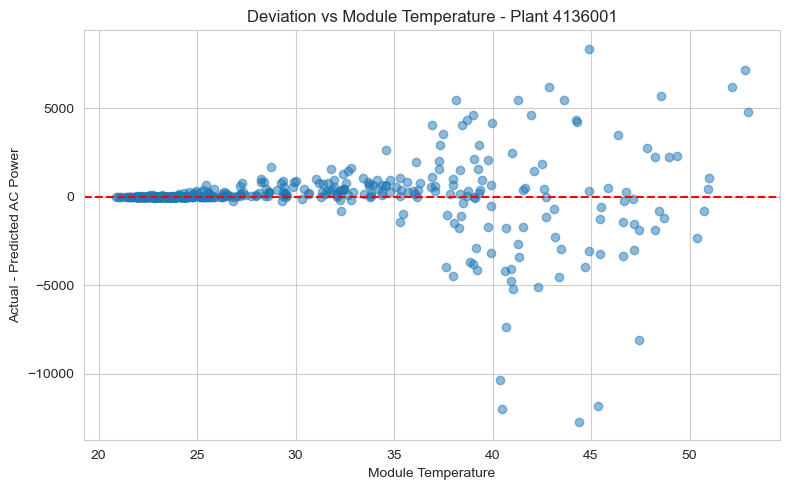

In [93]:
for plant in test_results["PLANT_ID"].unique():

    data = test_results[
        test_results["PLANT_ID"] == plant
    ]

    plt.figure(figsize=(8, 5))

    plt.scatter(
        data["MODULE_TEMPERATURE"],
        data["Deviation"],
        alpha=0.5
    )

    plt.axhline(0, color="red", linestyle="--")

    plt.title(f"Deviation vs Module Temperature - Plant {plant}")
    plt.xlabel("Module Temperature")
    plt.ylabel("Actual - Predicted AC Power")
    plt.tight_layout()
    plt.show()

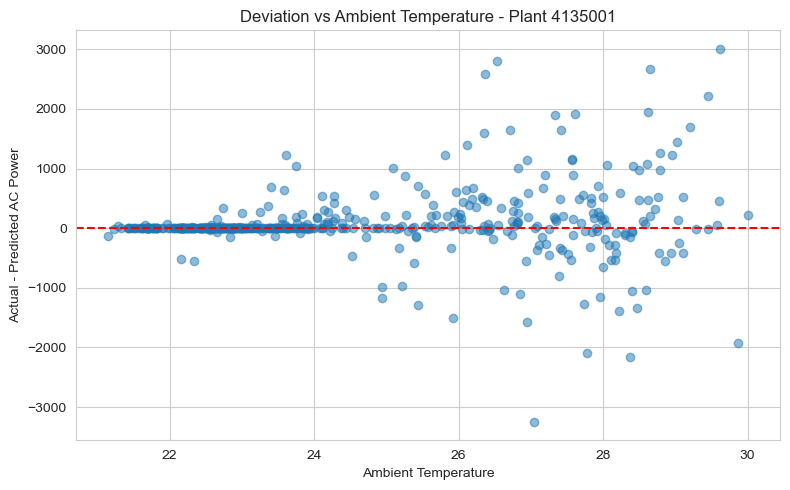

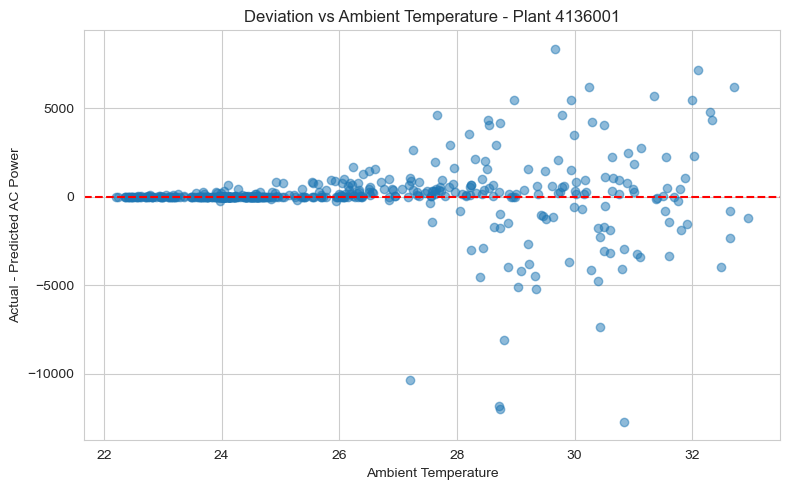

In [94]:
for plant in test_results["PLANT_ID"].unique():

    data = test_results[
        test_results["PLANT_ID"] == plant
    ]

    plt.figure(figsize=(8, 5))

    plt.scatter(
        data["AMBIENT_TEMPERATURE"],
        data["Deviation"],
        alpha=0.5
    )

    plt.axhline(0, color="red", linestyle="--")

    plt.title(f"Deviation vs Ambient Temperature - Plant {plant}")
    plt.xlabel("Ambient Temperature")
    plt.ylabel("Actual - Predicted AC Power")
    plt.tight_layout()
    plt.show()


In [96]:
test_results["Absolute_Deviation"] = (
    test_results["Deviation"].abs()
)
for plant in test_results["PLANT_ID"].unique():

    data = test_results[
        test_results["PLANT_ID"] == plant
    ]

    Q1 = data["Absolute_Deviation"].quantile(0.25)
    Q3 = data["Absolute_Deviation"].quantile(0.75)

    IQR = Q3 - Q1
    threshold = Q3 + 1.5 * IQR

    unusual = data[
        data["Absolute_Deviation"] > threshold
    ]

    print("Plant:", plant)
    print("Threshold:", threshold)
    print("Unusual observations:", len(unusual))
    print("Total observations:", len(data))
    print("--------------------------------")

Plant: 4135001
Threshold: 666.8419061018253
Unusual observations: 56
Total observations: 488
--------------------------------
Plant: 4136001
Threshold: 1558.0179938477413
Unusual observations: 70
Total observations: 490
--------------------------------


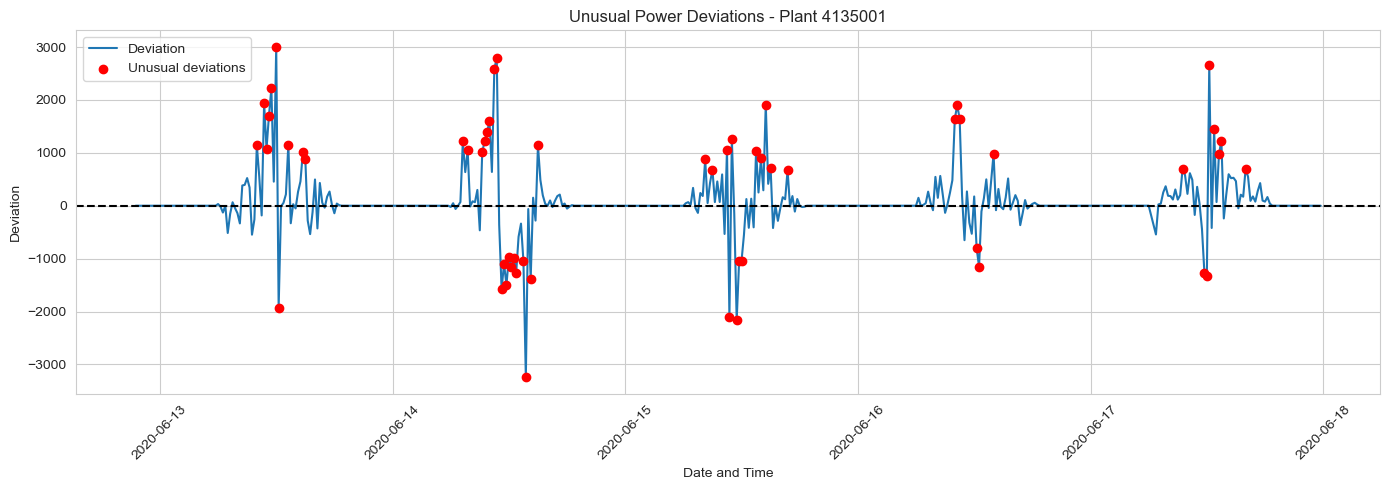

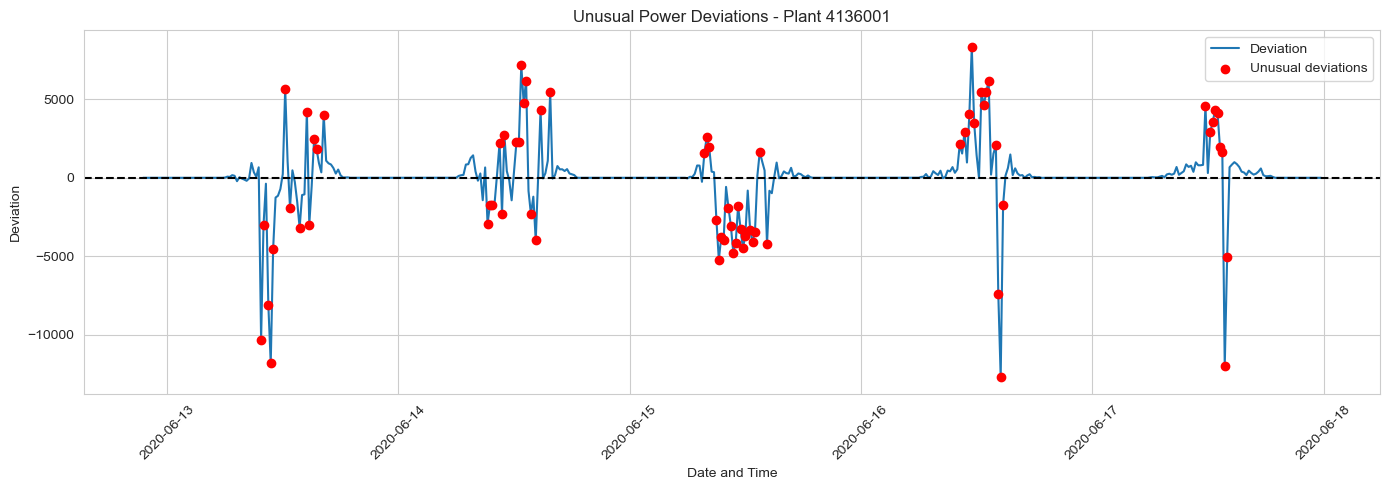

In [97]:
for plant in test_results["PLANT_ID"].unique():

    data = test_results[
        test_results["PLANT_ID"] == plant
    ].sort_values("DATE_TIME")

    Q1 = data["Absolute_Deviation"].quantile(0.25)
    Q3 = data["Absolute_Deviation"].quantile(0.75)
    threshold = Q3 + 1.5 * (Q3 - Q1)

    unusual = data[
        data["Absolute_Deviation"] > threshold
    ]

    plt.figure(figsize=(14, 5))

    plt.plot(
        data["DATE_TIME"],
        data["Deviation"],
        label="Deviation"
    )

    plt.scatter(
        unusual["DATE_TIME"],
        unusual["Deviation"],
        color="red",
        label="Unusual deviations",
        zorder=3
    )

    plt.axhline(0, color="black", linestyle="--")

    plt.title(f"Unusual Power Deviations - Plant {plant}")
    plt.xlabel("Date and Time")
    plt.ylabel("Deviation")
    plt.legend()
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [98]:
for plant in test_results["PLANT_ID"].unique():

    data = test_results[
        test_results["PLANT_ID"] == plant
    ]

    Q1 = data["Absolute_Deviation"].quantile(0.25)
    Q3 = data["Absolute_Deviation"].quantile(0.75)
    threshold = Q3 + 1.5 * (Q3 - Q1)

    unusual = data[
        data["Absolute_Deviation"] > threshold
    ]

    print("\nPlant:", plant)

    display(
        unusual.sort_values(
            "Absolute_Deviation",
            ascending=False
        ).head(10)
    )


Plant: 4135001


,DATE_TIME,PLANT_ID,AC_POWER,DC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,HOUR,TIME_SIN,TIME_COS,Actual_AC_POWER,Predicted_AC_POWER,Deviation,Absolute_Deviation
5761,2020-06-14 13:45:00,4135001,23086.444643,236500.125000,27.048904,47.960231,0.906615,13,-4.422887e-01,-0.896873,23086.444643,26331.156524,-3244.711881,3244.711881
5556,2020-06-13 12:00:00,4135001,27843.317856,285532.607130,29.614476,54.576355,0.958228,12,1.224647e-16,-1.000000,27843.317856,24839.024210,3004.293646,3004.293646
5737,2020-06-14 10:45:00,4135001,24517.432143,251087.732140,26.533364,42.528473,0.833045,10,3.214395e-01,-0.946930,24517.432143,21720.692043,2796.740100,2796.740100
6324,2020-06-17 12:15:00,4135001,29048.955358,297928.392870,28.649095,53.773537,1.031230,12,-6.540313e-02,-0.997859,29048.955358,26381.006045,2667.949313,2667.949313
5735,2020-06-14 10:30:00,4135001,22742.316072,232813.392851,26.360058,38.927488,0.719525,10,3.826834e-01,-0.923880,22742.316072,20157.855733,2584.460339,2584.460339
5552,2020-06-13 11:30:00,4135001,26818.498215,275000.375010,29.450120,53.953094,0.855400,11,1.305262e-01,-0.991445,26818.498215,24599.907382,2218.590833,2218.590833
5935,2020-06-15 11:30:00,4135001,17740.719643,181471.607142,28.375456,45.724137,0.637089,11,1.305262e-01,-0.991445,17740.719643,19905.630128,-2164.910485,2164.910485
5929,2020-06-15 10:45:00,4135001,23058.732144,236207.339273,27.778299,46.052281,0.860845,10,3.214395e-01,-0.946930,23058.732144,25159.053019,-2100.320875,2100.320875
5546,2020-06-13 10:45:00,4135001,23407.569642,239880.464278,28.622086,50.498668,0.740382,10,3.214395e-01,-0.946930,23407.569642,21466.574567,1940.995075,1940.995075
5558,2020-06-13 12:15:00,4135001,23390.046429,239571.553563,29.873128,53.625722,0.889302,12,-6.540313e-02,-0.997859,23390.046429,25315.686202,-1925.639773,1925.639773



Plant: 4136001


,DATE_TIME,PLANT_ID,AC_POWER,DC_POWER,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION,HOUR,TIME_SIN,TIME_COS,Actual_AC_POWER,Predicted_AC_POWER,Deviation,Absolute_Deviation
6151,2020-06-16 14:30:00,4136001,0.000000,0.000000,30.833513,44.376507,0.562944,14,-0.608761,-0.793353,0.000000,12696.663038,-12696.663038,12696.663038
6335,2020-06-17 13:45:00,4136001,1743.614286,1781.924286,28.731198,40.460310,0.578941,13,-0.442289,-0.896873,1743.614286,13737.568192,-11993.953906,11993.953906
5545,2020-06-13 10:45:00,4136001,0.000000,0.000000,28.721466,45.337588,0.503415,10,0.321439,-0.946930,0.000000,11806.115086,-11806.115086,11806.115086
5537,2020-06-13 09:45:00,4136001,5864.740000,5990.160000,27.204436,40.380066,0.607118,9,0.555570,-0.831470,5864.740000,16186.385750,-10321.645750,10321.645750
6127,2020-06-16 11:30:00,4136001,22419.533333,22953.673333,29.671495,44.916273,0.768459,11,0.130526,-0.991445,22419.533333,14087.625225,8331.908108,8331.908108
5543,2020-06-13 10:30:00,4136001,3506.090000,3594.392857,28.801169,47.455201,0.794066,10,0.382683,-0.923880,3506.090000,11592.685220,-8086.595220,8086.595220
6150,2020-06-16 14:15:00,4136001,4860.438571,4962.125238,30.429874,40.680056,0.492803,14,-0.555570,-0.831470,4860.438571,12236.129577,-7375.691006,7375.691006
5754,2020-06-14 12:45:00,4136001,15244.790952,15620.360476,32.103895,52.801106,0.884950,12,-0.195090,-0.980785,15244.790952,8083.009808,7161.781145,7161.781145
5758,2020-06-14 13:15:00,4136001,14602.326190,14971.370000,32.706111,52.174472,0.887381,13,-0.321439,-0.946930,14602.326190,8418.450663,6183.875527,6183.875527
6141,2020-06-16 13:15:00,4136001,18387.292381,18791.837619,30.244002,42.888082,0.566546,13,-0.321439,-0.946930,18387.292381,12219.735242,6167.557139,6167.557139


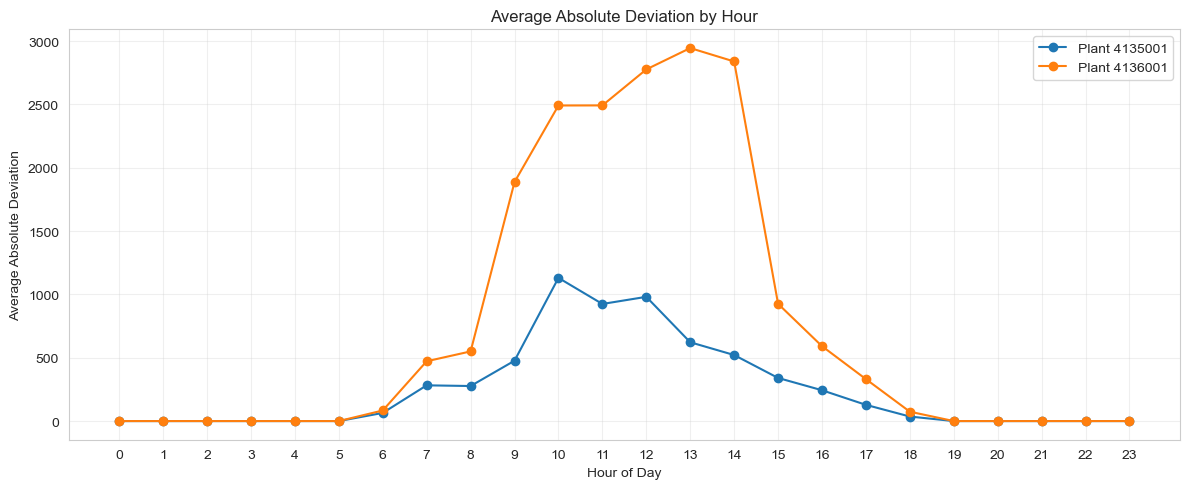

In [99]:
test_results["HOUR"] = test_results["DATE_TIME"].dt.hour

plt.figure(figsize=(12, 5))

for plant in test_results["PLANT_ID"].unique():

    data = test_results[
        test_results["PLANT_ID"] == plant
    ]

    hourly_error = data.groupby("HOUR")["Absolute_Deviation"].mean()

    plt.plot(
        hourly_error.index,
        hourly_error.values,
        marker="o",
        label=f"Plant {plant}"
    )

plt.title("Average Absolute Deviation by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Absolute Deviation")
plt.xticks(range(0, 24))
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\mushi\AppData\Local\Temp\ipykernel_18460\1521481727.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(


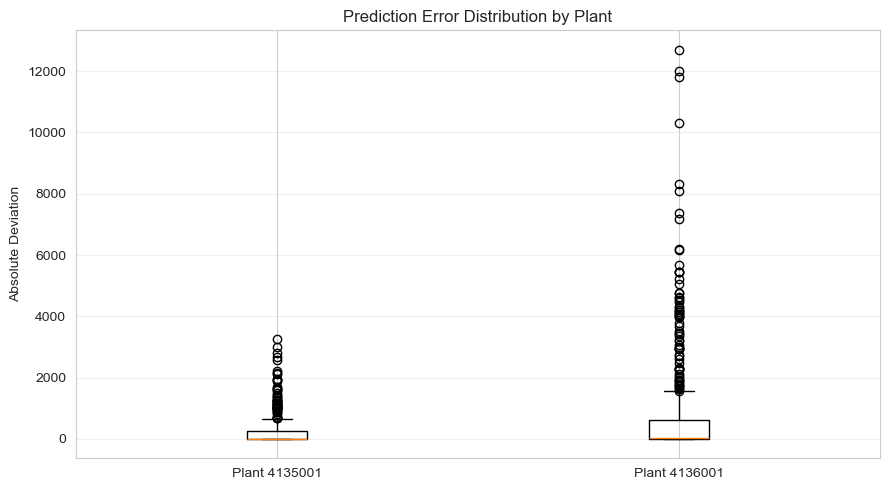

In [100]:
plt.figure(figsize=(9, 5))

plt.boxplot(
    [
        test_results[test_results["PLANT_ID"] == plant]["Absolute_Deviation"]
        for plant in test_results["PLANT_ID"].unique()
    ],
    labels=["Plant 4135001", "Plant 4136001"]
)

plt.title("Prediction Error Distribution by Plant")
plt.ylabel("Absolute Deviation")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

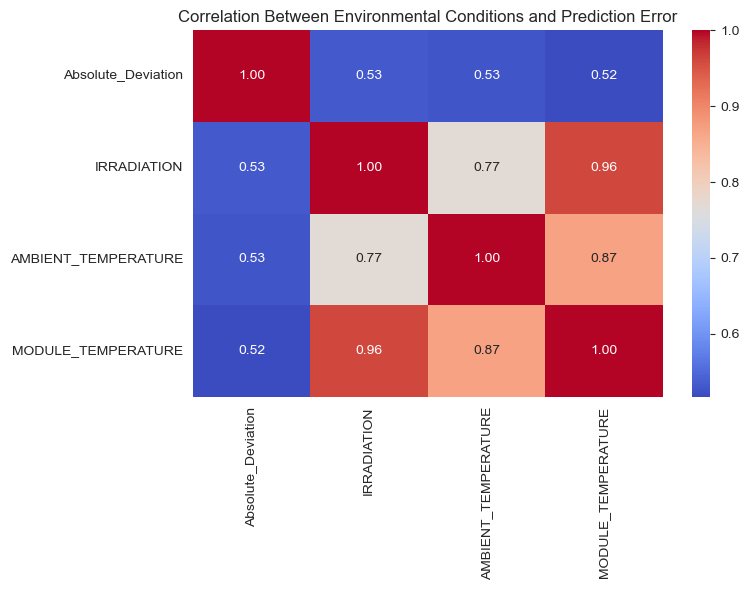

In [101]:
error_corr = test_results[
    [
        "Absolute_Deviation",
        "IRRADIATION",
        "AMBIENT_TEMPERATURE",
        "MODULE_TEMPERATURE"
    ]
].corr()

plt.figure(figsize=(8, 6))

import seaborn as sns

sns.heatmap(
    error_corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Between Environmental Conditions and Prediction Error")
plt.tight_layout()
plt.show()

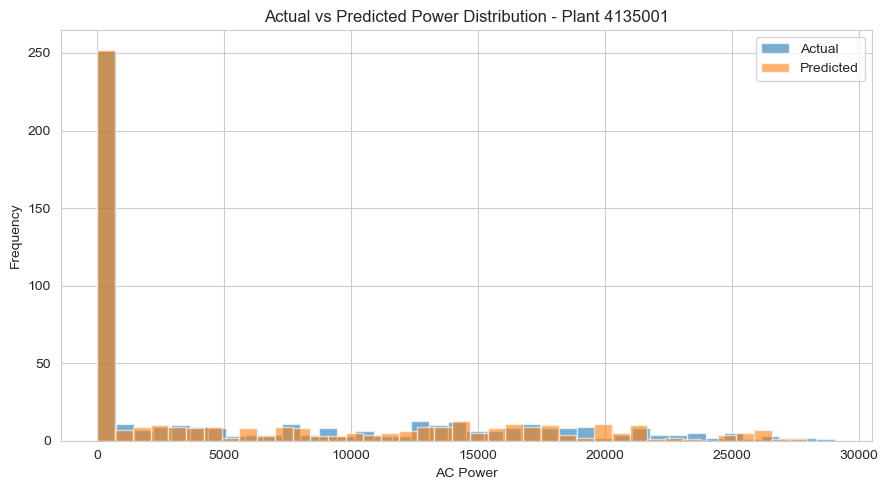

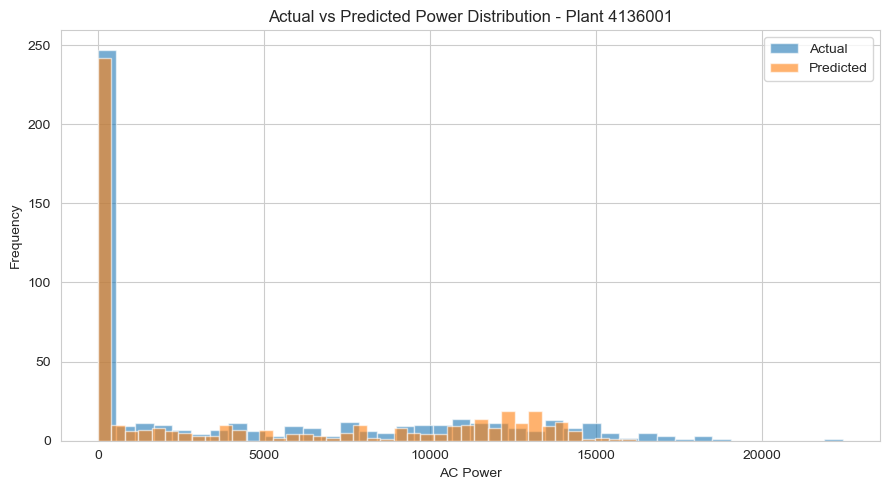

In [102]:
for plant in test_results["PLANT_ID"].unique():

    data = test_results[
        test_results["PLANT_ID"] == plant
    ]

    plt.figure(figsize=(9, 5))

    plt.hist(
        data["Actual_AC_POWER"],
        bins=40,
        alpha=0.6,
        label="Actual"
    )

    plt.hist(
        data["Predicted_AC_POWER"],
        bins=40,
        alpha=0.6,
        label="Predicted"
    )

    plt.title(f"Actual vs Predicted Power Distribution - Plant {plant}")
    plt.xlabel("AC Power")
    plt.ylabel("Frequency")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
import joblib
import os

os.makedirs("saved_models", exist_ok=True)

models = {
    "linear_regression": lr_model,
    "ridge": best_ridge,
    "lasso": best_lasso,
    "svr": svr_grid.best_estimator_,
    "random_forest": best_rf
}

for name, model in models.items():

    joblib.dump(
        model,
        f"saved_models/{name}.pkl"
    )

    print(name, "saved successfully!")